# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.

**NOTA**: Ambos os datasets são refetentes ao mês de setembro de 2018.  

In [1]:
#CÉLULA TCC-01
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator

In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-0
dataSetFotoVoltaico = ['Fotovoltaico_Jul_2018.csv','Fotovoltaico_Ago_2018.csv','Fotovoltaico_Sep_2018.csv']

In [7]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2108090 entries, 2018-07-01 00:00:01.590000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 144.8 MB


In [7]:
#CÉLULA TCC-0
#dfRawFoto = loadDataFile('input/Fotovoltaico_Sep_2018.csv', True) 
#dfRawFoto.info()

In [8]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâne, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [9]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [10]:
#CÉLULA TCC-
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [11]:
#CÉLULA TCC-
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [12]:
#CÉLULA TCC-
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 523377 entries, 2018-07-01 00:00:06.897000 to 2018-09-30 23:58:49.283000
Data columns (total 3 columns):
painel         523377 non-null float64
energia_dia    523377 non-null float64
potencia       523377 non-null float64
dtypes: float64(3)
memory usage: 16.0 MB


In [13]:
#CÉLULA TCC-
dfRawFoto1['energia']  = dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1)

In [14]:
#CÉLULA TCC-
dfRawFoto1[dfRawFoto1 < 0] = 0

In [15]:
#CÉLULA TCC-
dfRawFoto1.drop({'energia_dia'},axis=1, inplace=True)

In [16]:
#CÉLULA TCC-
dfRawFoto1.fillna(0, inplace=True)

In [17]:
#CÉLULA TCC-
dfRawFoto1.isna().sum()

painel      0
potencia    0
energia     0
dtype: int64

In [18]:
dfRawFoto1.head()

,painel,potencia,energia
data,,,
2018-07-01 00:00:06.897,1.0,0.0,0.0
2018-07-01 00:00:10.697,1.0,0.0,0.0
2018-07-01 00:00:28.477,1.0,0.0,0.0
2018-07-01 00:00:48.993,1.0,0.0,0.0
2018-07-01 00:01:07.387,1.0,0.0,0.0


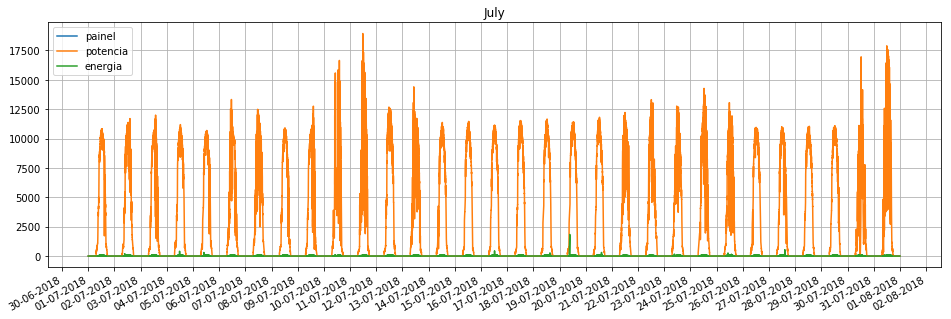

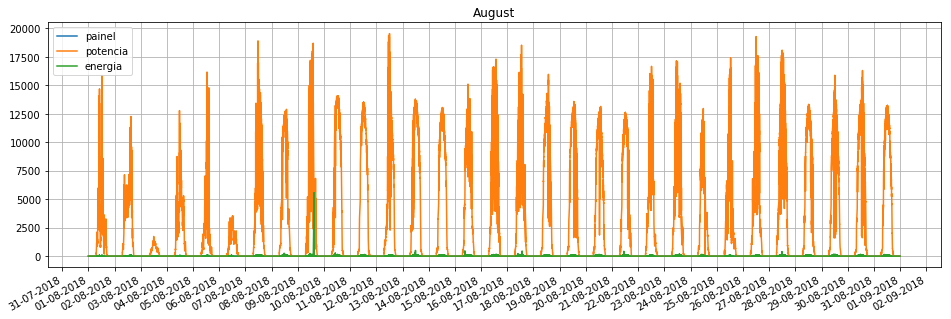

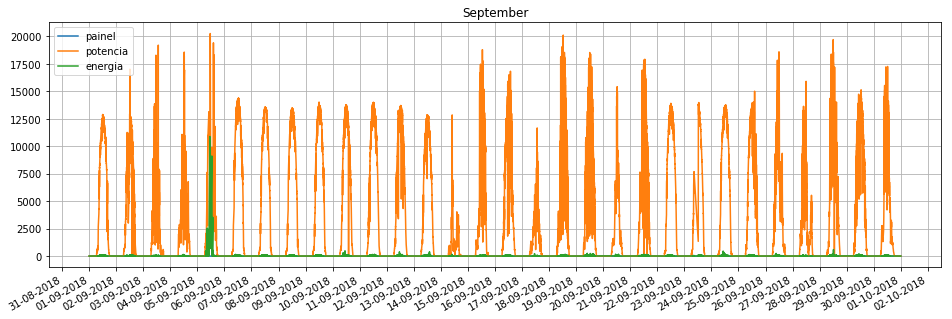

In [19]:
#CÉLULA TCC-
#deixar somente energia ????????
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [43]:
a = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2018-09-05 09:00:00') & (dfRawFoto1.reset_index()['data'] <= '2018-09-05 19:00:00') ]
a.set_index('data',inplace=True)
a.head(50)

,painel,potencia,energia
data,,,
2018-09-05 09:01:11.360,1.0,2750.0,1390.0
2018-09-05 09:05:58.770,1.0,8023.0,480.0
2018-09-05 09:14:33.787,1.0,9762.0,1216.0
2018-09-05 09:14:39.127,1.0,8836.0,4.0
2018-09-05 09:14:39.680,1.0,8836.0,0.0
2018-09-05 09:14:40.333,1.0,10843.0,10.0
2018-09-05 09:14:41.513,1.0,10843.0,0.0
2018-09-05 09:14:41.677,1.0,10978.0,6.0
2018-09-05 09:21:43.737,1.0,10790.0,1020.0


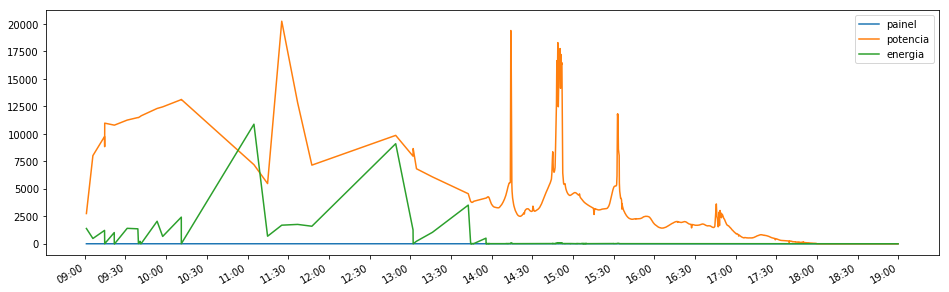

In [44]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.grid()
#showDataPlot(dfRawFoto1)
##Dividir gráficos
plt.grid()
plt.plot(a)
plt.gca().legend(a.columns)
plt.gca().xaxis.set_major_locator(MinuteLocator(byminute=(0,30,0)))#DayLocator(interval=5)
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M'))
plt.gcf().autofmt_xdate()
plt.show()

## 1.2 - Análise do dataset meteorológico

In [45]:
#CÉLULA TCC-0
dataSetMeteorologico = ['Meteorologico_Jul_2018.csv','Meteorologico_Ago_2018.csv','Meteorologico_Sep_2018.csv']

In [46]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetMeteorologico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 13120 entries, 2018-07-01 00:00:07 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         13120 non-null float64
deficit_vapor_vmedio       13120 non-null float64
ponto_orvalho_vmin         13120 non-null float64
ponto_orvalho_vmedio       13120 non-null float64
precipitacao_valor         13120 non-null float64
radiacao_solar_valor       13120 non-null float64
temperatura_ar_vmin        13120 non-null float64
temperatura_ar_vmedio      13120 non-null float64
temperatura_ar_vmax        13120 non-null float64
umidade_ar_vmin            13120 non-null float64
umidade_ar_vmedio          13120 non-null float64
umidade_ar_vmax            13120 non-null float64
velocidade_vento_vmedio    13120 non-null float64
velocidade_vento_vmax      13120 non-null float64
dtypes: float64(14)
memory usage: 1.5 MB


In [47]:
#CÉLULA TCC-
#dfRawMete = loadDataFile('input/Meteorologico_Sep_2018.csv', True) 
#dfRawMete.info()

In [48]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    #'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    #'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    #'velocidade_vento_vmedio',
    #'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [49]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [50]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01 00:00:07,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
2018-07-01 00:10:07,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2018-07-01 00:20:07,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
2018-07-01 00:30:06,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
2018-07-01 00:40:07,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0


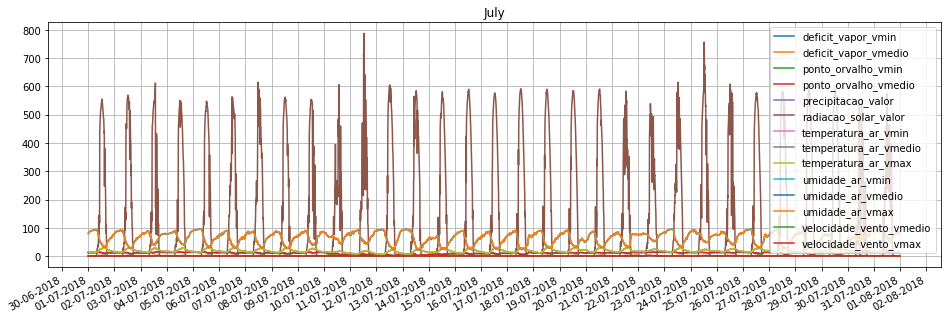

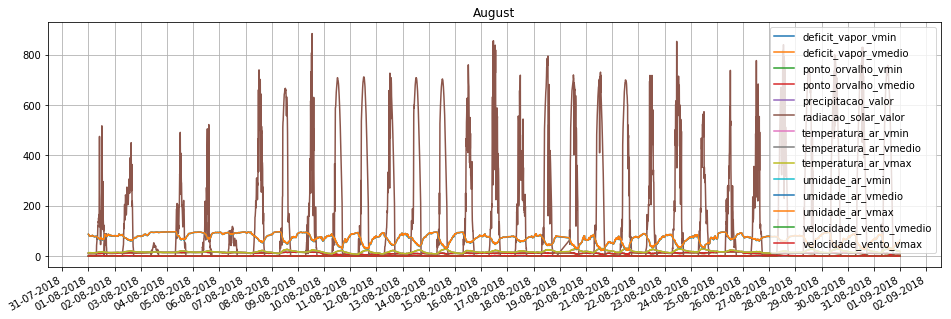

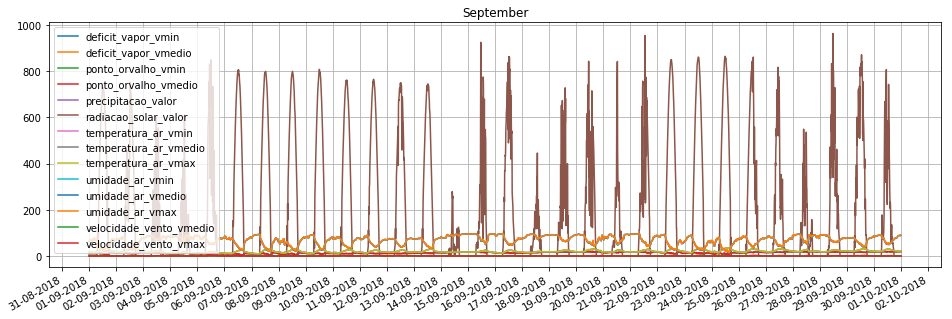

In [51]:
#CÉLULA TCC-
#plt.figure(figsize=(16,5))
#showDataPlot(dfRawMete)
for m in dfRawMete.groupby(by=[dfRawMete.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

## 1.3.1 - DownSample

In [52]:
dfRawFoto1.head()

,painel,potencia,energia
data,,,
2018-07-01 00:00:06.897,1.0,0.0,0.0
2018-07-01 00:00:10.697,1.0,0.0,0.0
2018-07-01 00:00:28.477,1.0,0.0,0.0
2018-07-01 00:00:48.993,1.0,0.0,0.0
2018-07-01 00:01:07.387,1.0,0.0,0.0


In [53]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample('10T') #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    "potencia":'mean',
    "energia":'sum'
})
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  potencia  energia
data                                          
2018-07-01 00:00:00     1.0       0.0      0.0
2018-07-01 00:10:00     1.0       0.0      0.0
2018-07-01 00:20:00     1.0       0.0      0.0
2018-07-01 00:30:00     1.0       0.0      0.0
2018-07-01 00:40:00     1.0       0.0      0.0


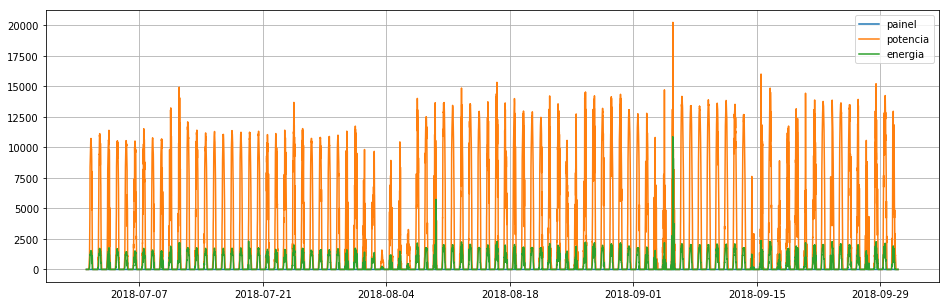

In [54]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownFoto)
##Dividir gráficos

## 1.3.2 - UpSample

In [55]:
#CÉLULA TCC-
downMete = dfRawMete.resample('10T') #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    'temperatura_ar_vmax':'max',
    'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    'umidade_ar_vmax':'max',
    'velocidade_vento_vmedio':'mean',
    'velocidade_vento_vmax':'max'
})
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head(50)

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01 00:00:00,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
2018-07-01 00:10:00,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2018-07-01 00:20:00,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
2018-07-01 00:30:00,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
2018-07-01 00:40:00,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0
2018-07-01 00:50:00,0.25,0.26,11.9,11.9,0.0,0.0,14.51,14.59,14.68,83.66,84.01,84.37,0.0,0.0
2018-07-01 01:00:00,0.24,0.24,12.0,12.1,0.0,0.0,14.54,14.58,14.63,85.20,85.37,85.55,0.0,0.0
2018-07-01 01:10:00,0.24,0.24,12.1,12.1,0.0,0.0,14.61,14.61,14.61,85.29,85.29,85.29,0.0,0.0
2018-07-01 01:20:00,0.23,0.23,12.0,12.0,0.0,0.0,14.44,14.50,14.57,85.66,85.74,85.83,0.0,0.0


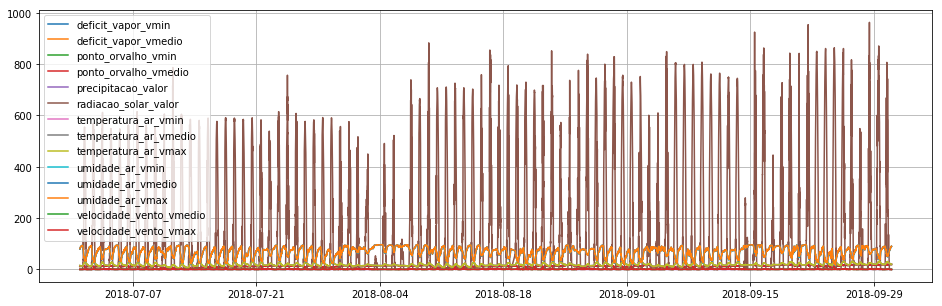

In [56]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownMete)
##Dividir gráficos

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [57]:
#CÉLULA TCC-
import seaborn as sns

In [58]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
dfSet1.reset_index(inplace=True)

In [59]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13248 entries, 0 to 13247
Data columns (total 18 columns):
data                       13248 non-null datetime64[ns]
painel                     13248 non-null float64
potencia                   13248 non-null float64
energia                    13248 non-null float64
deficit_vapor_vmin         13248 non-null float64
deficit_vapor_vmedio       13248 non-null float64
ponto_orvalho_vmin         13248 non-null float64
ponto_orvalho_vmedio       13248 non-null float64
precipitacao_valor         13248 non-null float64
radiacao_solar_valor       13248 non-null float64
temperatura_ar_vmin        13248 non-null float64
temperatura_ar_vmedio      13248 non-null float64
temperatura_ar_vmax        13248 non-null float64
umidade_ar_vmin            13248 non-null float64
umidade_ar_vmedio          13248 non-null float64
umidade_ar_vmax            13248 non-null float64
velocidade_vento_vmedio    13248 non-null float64
velocidade_vento_vmax      13248 n

In [60]:
#CÉLULA TCC-
saveDataFile(dfSet1,'FotoMet_P1_All_2018.csv')
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [61]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_P1_All_2018.csv', False)
#dfSet1 = loadDataFile('input/FotoMet_P1_Sep_2018.csv', False)

In [62]:
#CÉLULA TCC-
dfSet1.describe()

,painel,potencia,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,13248.0,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000
mean,1.0,2714.450370,352.065897,0.855713,0.868935,11.961402,12.034239,0.013368,134.936594,18.954175,19.047538,19.145791,67.413205,67.824433,68.240754,0.440195,0.527174
std,0.0,4216.118885,607.046166,0.809210,0.821144,3.138327,3.117492,0.122683,223.391858,5.282305,5.316212,5.351902,19.684470,19.535295,19.396850,0.548570,0.600718
min,1.0,0.000000,0.000000,0.040000,0.040000,0.100000,0.500000,0.000000,0.000000,5.100000,5.140000,5.180000,14.180000,15.560000,15.690000,0.000000,0.000000
25%,1.0,0.000000,0.000000,0.280000,0.290000,10.200000,10.200000,0.000000,0.000000,15.240000,15.290000,15.360000,53.257500,53.860000,54.370000,0.000000,0.000000
50%,1.0,0.000000,0.000000,0.540000,0.540000,11.900000,12.000000,0.000000,0.000000,17.940000,18.020000,18.100000,71.970000,72.360000,72.770000,0.200000,0.300000
75%,1.0,4599.297965,572.000000,1.170000,1.190000,13.900000,13.900000,0.000000,192.000000,22.300000,22.430000,22.552500,82.520000,82.910000,83.360000,0.700000,0.900000
max,1.0,20256.000000,10883.000000,4.720000,4.790000,20.000000,21.000000,7.800000,963.000000,35.450000,35.470000,35.690000,96.800000,96.800000,96.810000,3.100000,3.800000


In [63]:
dfSet1[(dfSet1['data'] >= '2018-09-05 00:00:00') & (dfSet1['data'] <= '2018-09-05 24:59:59')].energia.sum()

54820.0

## 2 - Normalização

Descrição ...

In [64]:
#CÉLULA TCC-
df = dfSet1.drop(['data'],axis=1)

In [65]:
#CÉLULA TCC-
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,potencia,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,13248.0,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000,13248.000000
mean,0.0,0.134007,0.032350,0.174298,0.174513,0.596050,0.562646,0.001714,0.140121,0.456480,0.458541,0.457745,0.644314,0.643334,0.647815,0.141998,0.138730
std,0.0,0.208142,0.055779,0.172908,0.172872,0.157705,0.152073,0.015729,0.231975,0.174046,0.175279,0.175415,0.238253,0.240464,0.239113,0.176958,0.158084
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.000000,0.051282,0.052632,0.507538,0.473171,0.000000,0.000000,0.334102,0.334652,0.333661,0.472979,0.471443,0.476824,0.000000,0.000000
50%,0.0,0.000000,0.000000,0.106838,0.105263,0.592965,0.560976,0.000000,0.000000,0.423064,0.424662,0.423468,0.699467,0.699163,0.703649,0.064516,0.078947
75%,0.0,0.227059,0.052559,0.241453,0.242105,0.693467,0.653659,0.000000,0.199377,0.566722,0.570063,0.569403,0.827160,0.829025,0.834196,0.225806,0.236842
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [52]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

## 3 - Treinamento do modelo

Descrição ...

In [66]:
#CÉLULA TCC-
from sklearn import model_selection
from sklearn import linear_model
from sklearn.ensemble import RandomForestRegressor

from sklearn import metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [67]:
#CÉLULA TCC-
def showResultPlot(y_pred,y_test):
    plt.figure(figsize=(17,7))
    y_pred = y_pred.T

    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.gca().legend(('Previsão','Real'))
    #plt.xticks(range(0,1150,50))
    plt.grid()
    plt.show()

In [68]:
#CÉLULA TCC-
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)
    return model

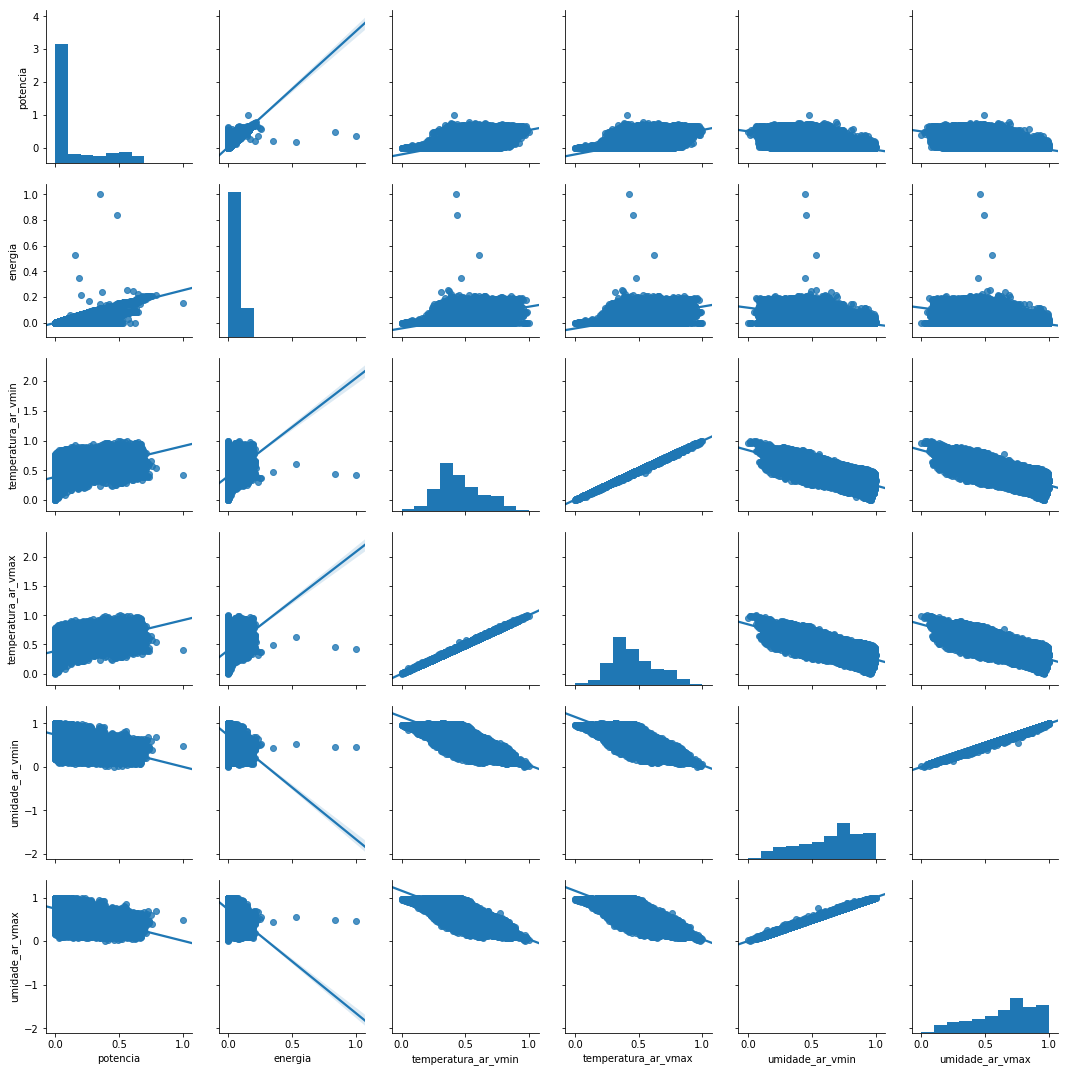

In [69]:
#CÉLULA TCC-
g = sns.pairplot(df.drop(['painel',
            #'potencia',
            #'energia',
            'deficit_vapor_vmin',
            'deficit_vapor_vmedio',
            'ponto_orvalho_vmin',
            'ponto_orvalho_vmedio',
            'precipitacao_valor',
            'radiacao_solar_valor',
            #'temperatura_ar_vmin',#
            'temperatura_ar_vmedio',
            #'temperatura_ar_vmax',#
            #'umidade_ar_vmin',#
            'umidade_ar_vmedio',
            #'umidade_ar_vmax',#
            'velocidade_vento_vmedio',
            'velocidade_vento_vmax'
            ],axis=1),kind="reg")#kind="reg"

In [70]:
#CÉLULA TCC-
X = df.drop(['painel',
            #'potencia',
            'energia',
            'deficit_vapor_vmin',
            'deficit_vapor_vmedio',
            'ponto_orvalho_vmin',
            'ponto_orvalho_vmedio',
            'precipitacao_valor',
            'radiacao_solar_valor',
            #'temperatura_ar_vmin',#
            'temperatura_ar_vmedio',
            #'temperatura_ar_vmax',#
            #'umidade_ar_vmin',#
            'umidade_ar_vmedio',
            #'umidade_ar_vmax',#
            'velocidade_vento_vmedio',
            'velocidade_vento_vmax'
            ],axis=1)
y = df.energia

In [71]:
#CÉLULA TCC-
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [72]:
#CÉLULA TCC-
print(X_train.shape)
print(y_train.shape)

(9936, 5)
(9936,)


In [73]:
#CÉLULA TCC-
print(X_test.shape)
print(y_test.shape)

(3312, 5)
(3312,)


Regressão  Linear

https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606

https://www.dataquest.io/blog/understanding-regression-error-metrics/

https://realpython.com/linear-regression-in-python/

https://www.analyticsvidhya.com/blog/2017/06/a-comprehensive-guide-for-linear-ridge-and-lasso-regression/

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000351
RMSE: 0.018740
r²: 88.92 %
MAE: 0.007120
------------------- TESTE ---------------------------
MSE: 0.000212
RMSE: 0.014544
r²: 92.79 %
MAE: 0.006865
----------------------------------------------------


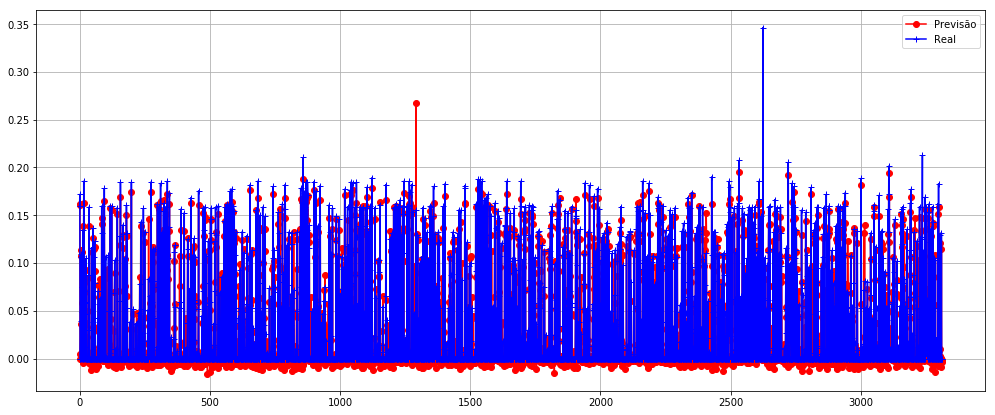

                     0  Coeficiente estimado
0             potencia              0.271048
4      umidade_ar_vmax              0.072017
2  temperatura_ar_vmax              0.017715
1  temperatura_ar_vmin             -0.039367
3      umidade_ar_vmin             -0.062246


In [74]:
#CÉLULA TCC-
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')
modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)
#print(model.intercept_)
coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True,ascending=False)
print(coeff)
#print(modelRegLinear.coef_)
#for idx, col_name in enumerate(X_train.columns):
#    print("Ccoeficiente para a coluna '{}': {:.6f}".format(col_name, model.coef_[idx]))


Random Forest Regressor

----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000042
RMSE: 0.006470
r²: 98.68 %
MAE: 0.001756
------------------- TESTE ---------------------------
MSE: 0.000191
RMSE: 0.013828
r²: 93.49 %
MAE: 0.004370
----------------------------------------------------


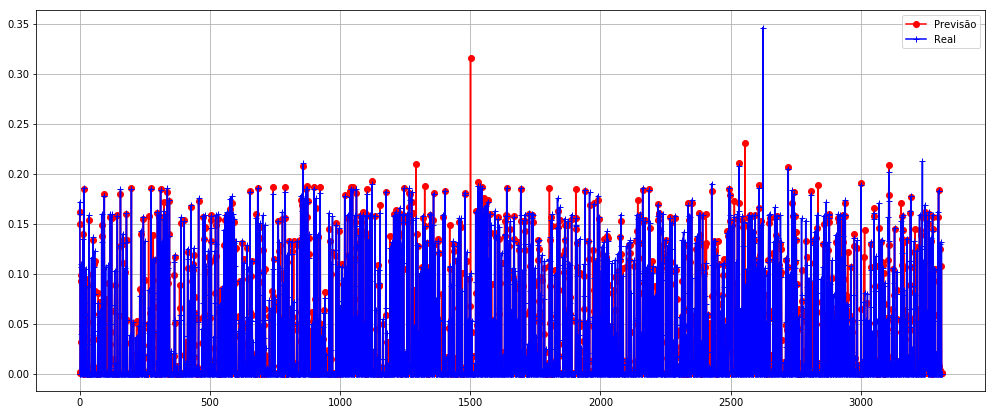

In [78]:
#CÉLULA TCC-
RandomForest = RandomForestRegressor(n_estimators=350, random_state=0)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

In [98]:
#MAE é a média da diferença absoluta entre os valores previstos e o valor observado

#O numerador é MSE (média dos quadrados dos residuais) e o denominador é a variância nos valores Y. Quanto mais alto o MSE, menor o R_squared e mais pobre é o modelo.

#Por que você deve escolher R² Ajustado sobre R²?
#Existem alguns problemas com o R² normal que são resolvidos pelo R² Ajustado. Um R² ajustado considerará a melhoria marginal adicionada por um termo adicional em seu modelo. Por isso, aumentará se você adicionar os termos úteis e diminuirá se você adicionar preditores menos úteis. No entanto, o R² aumenta com termos crescentes, mesmo que o modelo não esteja realmente melhorando.

#O R², também chamado de Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.

#RMSE (Root Mean Square Error)(Erro Quadrado Médio da Raiz)
#Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos)

In [99]:
#Teste F de Significância global: afirma se ao menos uma variável do meu modelo está relacionada com a variável alvo. Para isso, o valor-p desta estatística precisa ser menor que 0.05

#Teste de Significância individuais ou p-values dos coeficientes: diz o quanto das variáveis preditoras explicam a variável alvo. A métrica padrão é o p-value ser menor que 0.05.

#Coeficiente R²: diz o quanto o meu modelo explica seus resultados. É um valor entre 0 e 1. Quanto mais próximo de 1, melhor.

In [80]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns

def plot_residuals_and_coeff(resid_train, resid_test, coeff):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("núm. amostras")
    axes[0].set_ylabel("resíduo")
    axes[0].set_title("treino")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("núm. amostras")
    axes[1].set_ylabel("resíduo")
    axes[1].set_title("teste")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xlabel("núm. coeficientes")
    axes[2].set_ylabel("coeficiente")
    fig.tight_layout()
    return fig, axes

residuo_treino = y_train - modelRegLinear.predict(X_train)
residuo_teste  = y_test - modelRegLinear.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, modelRegLinear.coef_)

NameError: name 'modelRegLinear' is not defined

training score: 0.0
test score:  -0.0004392788402931557
number of features used:  0
training score for alpha=0.01: 0.16149815273209
test score for alpha =0.01:  0.1678437973792425
number of features used: for alpha =0.01: 1
training score for alpha=0.0001: 0.88852360368625
test score for alpha =0.0001:  0.9279032491444745
number of features used: for alpha =0.0001: 3
LR training score: 0.8891882238823514
LR test score:  0.9279373042845933


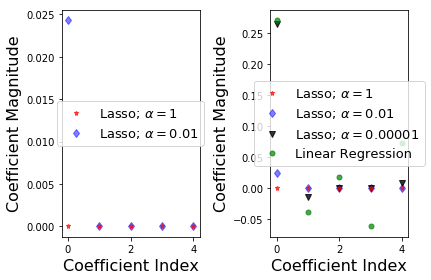

In [88]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import LinearRegression
from pandas import Series, DataFrame

lasso = Lasso()
lasso.fit(X_train,y_train)
train_score=lasso.score(X_train,y_train)
test_score=lasso.score(X_test,y_test)
coeff_used = np.sum(lasso.coef_!=0)

print("training score:" , train_score)
print("test score: " , test_score)
print("number of features used: ", coeff_used)

lasso001 = Lasso(alpha=0.01, max_iter=10e5)
lasso001.fit(X_train,y_train)

train_score001=lasso001.score(X_train,y_train)
test_score001=lasso001.score(X_test,y_test)
coeff_used001 = np.sum(lasso001.coef_!=0)

print("training score for alpha=0.01:", train_score001)
print("test score for alpha =0.01: ", test_score001)
print("number of features used: for alpha =0.01:", coeff_used001)

lasso00001 = Lasso(alpha=0.0001, max_iter=10e5)
lasso00001.fit(X_train,y_train)

train_score00001=lasso00001.score(X_train,y_train)
test_score00001=lasso00001.score(X_test,y_test)
coeff_used00001 = np.sum(lasso00001.coef_!=0)

print("training score for alpha=0.0001:", train_score00001)
print("test score for alpha =0.0001: ", test_score00001)
print("number of features used: for alpha =0.0001:", coeff_used00001)

lr = LinearRegression()
lr.fit(X_train,y_train)
lr_train_score=lr.score(X_train,y_train)
lr_test_score=lr.score(X_test,y_test)

print("LR training score:", lr_train_score)
print("LR test score: ", lr_test_score)

plt.subplot(1,2,1)
plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=10)

plt.subplot(1,2,2)

plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency
plt.plot(lasso00001.coef_,alpha=0.8,linestyle='none',marker='v',markersize=6,color='black',label=r'Lasso; $\alpha = 0.00001$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.7,linestyle='none',marker='o',markersize=5,color='green',label='Linear Regression',zorder=2)

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=10)
plt.tight_layout()
plt.show()

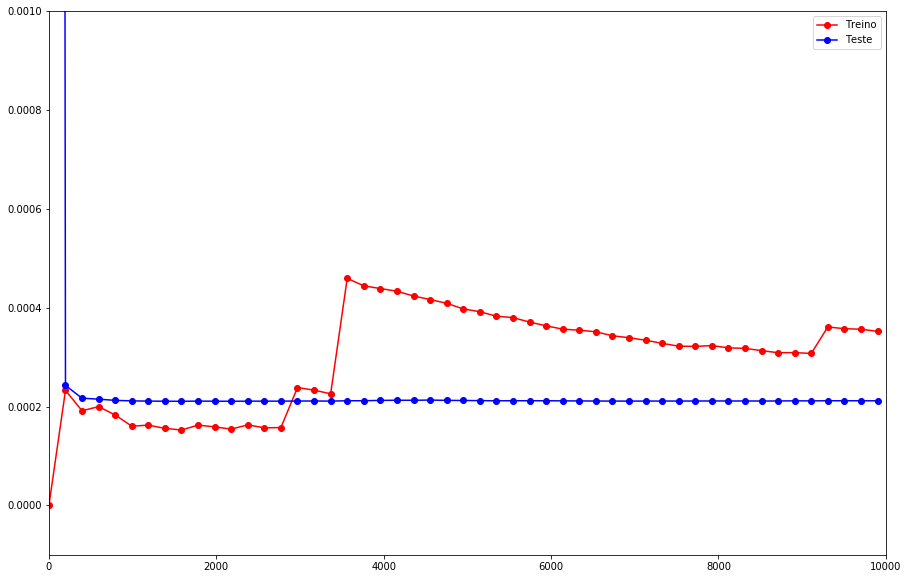

In [130]:
n_amostras = list(range(1, X_train.shape[0], int(X_train.shape[0]/50)))#encremento dos dados,50 partes
resultados_treino = []
resultados_teste  = []

# suponha dividir todos os dados em 10 partes
for i in n_amostras:
    model = linear_model.LinearRegression()
    model.fit(X_train[:i], y_train[:i])
    resultados_treino.append(metrics.mean_squared_error(model.predict(X_train[:i]), y_train[:i]))
    resultados_teste.append(metrics.mean_squared_error(model.predict(X_test), y_test))

    
plt.figure(figsize=(15,10))
# set axes range
plt.xlim(-0.001, 10000)
plt.ylim(-0.0001,0.001)
plt.plot(n_amostras, resultados_treino, 'o-', color="r", label="Treino")
plt.plot(n_amostras, resultados_teste, 'o-', color="b", label="Teste")
plt.legend(loc='best')
plt.show()

## 4 - Otimização

## 5 - Resultados